In [1]:
import os
import zipfile
import urllib.request

url = "https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip"
zip_name = "catsdogs.zip"

if not os.path.exists(zip_name):
    print("开始下载数据集...")
    urllib.request.urlretrieve(url, zip_name)
    print("下载完成")

print("开始解压...")
with zipfile.ZipFile(zip_name, 'r') as zf:
    zf.extractall("./catsdogs")
print("解压完成！")

开始解压...
解压完成！


猫图片数量：12500
狗图片数量：12500


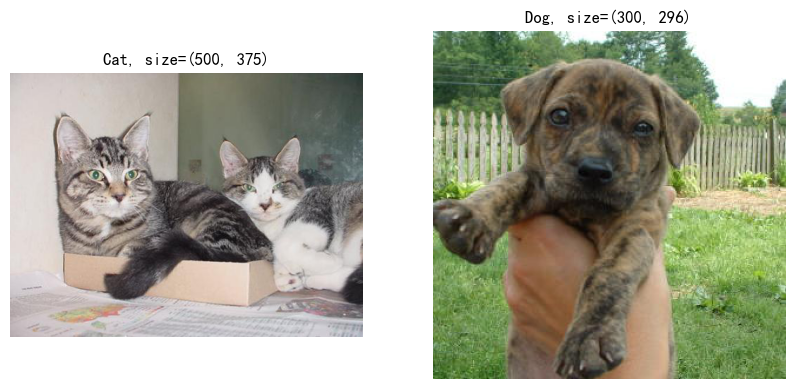

In [2]:
import os
from PIL import Image
import matplotlib.pyplot as plt
import random
import numpy as np

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader,random_split
from torchvision import datasets,transforms
from torchvision.transforms import ToTensor

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False



data_root = "./catsdogs/PetImages"
cat_dir = os.path.join(data_root, "Cat")
dog_dir = os.path.join(data_root, "Dog")

cat_files = [f for f in os.listdir(cat_dir) if f.endswith(".jpg")]
dog_files = [f for f in os.listdir(dog_dir) if f.endswith(".jpg")]

print(f"猫图片数量：{len(cat_files)}")
print(f"狗图片数量：{len(dog_files)}")

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
rand_cat_name = random.choice(cat_files)
img_cat = Image.open(os.path.join(cat_dir, rand_cat_name))
plt.imshow(img_cat)
plt.title(f"Cat, size={img_cat.size}")
plt.axis("off")

plt.subplot(1, 2, 2)
rand_dog_name = random.choice(dog_files)
img_dog = Image.open(os.path.join(dog_dir, rand_dog_name))
plt.imshow(img_dog)
plt.title(f"Dog, size={img_dog.size}")
plt.axis("off")

plt.show()

In [3]:
def clean_broken_img(folder):
    count = 0
    for filename in os.listdir(folder):
        path = os.path.join(folder, filename)
        if filename.lower().endswith(".jpg"):
            try:
                img = Image.open(path)
                img.verify() 
            except Exception:
                os.remove(path)
                count += 1
    print(f"文件夹{folder}删除损坏的图片数量：{count}")
clean_broken_img(cat_dir)
clean_broken_img(dog_dir)

文件夹./catsdogs/PetImages\Cat删除损坏的图片数量：1


c:\Users\17001\anaconda3\envs\torch_env\lib\site-packages\PIL\TiffImagePlugin.py:949: UserWarning: Truncated File Read
  warnings.warn(str(msg))


文件夹./catsdogs/PetImages\Dog删除损坏的图片数量：1


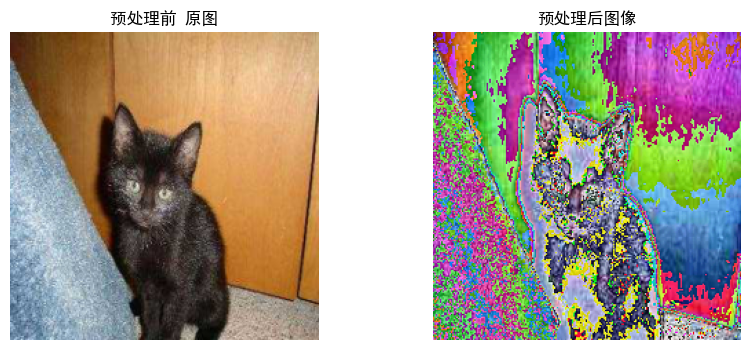

图片类别标签：0 （0=猫，1=狗）


In [4]:
transform_basic = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

transform_raw = transforms.Compose([
    transforms.Resize((224,224))
])

transform_aug = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

transform_val_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

dataset_raw = datasets.ImageFolder(root=data_root, transform=transform_raw)
dataset_train_all = datasets.ImageFolder(root=data_root, transform=transform_aug)

rand_idx = random.randint(0, len(dataset_raw)-1)
img_original, label = dataset_raw[rand_idx]
img_tensor_processed, _ = dataset_train_all[rand_idx]
img_processed = transforms.ToPILImage()(img_tensor_processed)

plt.figure(figsize=(10, 4))
plt.subplot(1,2,1)
plt.title("预处理前 原图")
plt.imshow(img_original)
plt.axis("off")

plt.subplot(1,2,2)
plt.title("预处理后图像")
plt.imshow(img_processed)
plt.axis("off")
plt.show()
print(f"图片类别标签：{label} （0=猫，1=狗）")
full_dataset = datasets.ImageFolder(root=data_root, transform=None)



In [5]:
train_len = int(0.7 * len(full_dataset))
val_len = int(0.15 * len(full_dataset))
test_len = len(full_dataset) - train_len - val_len
train_set_raw, val_set_raw, test_set_raw = random_split(full_dataset, [train_len, val_len, test_len])


In [6]:
class MySubset(Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        img, label = self.subset[idx]
        if self.transform:
            img = self.transform(img)
        return img, label

In [7]:
train_dataset = MySubset(train_set_raw, transform_aug)
val_dataset = MySubset(val_set_raw, transform_val_test)
test_dataset = MySubset(test_set_raw, transform_val_test)

In [8]:
batch_size = 16
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

print(f"训练集：{len(train_dataset)}")
print(f"验证集：{len(val_dataset)}")
print(f"测试集：{len(test_dataset)}")

训练集：17498
验证集：3749
测试集：3751


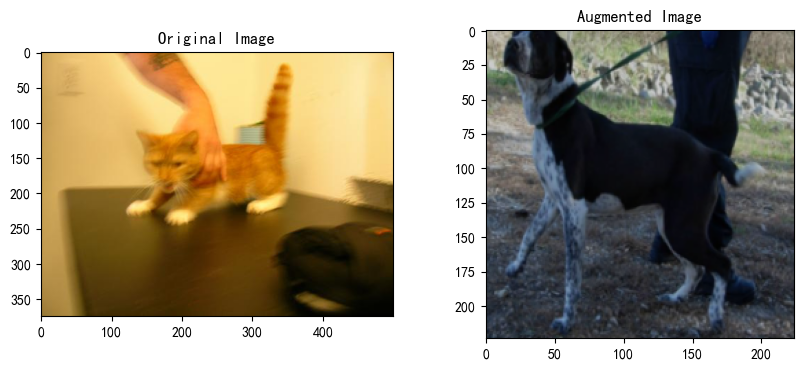

In [9]:
def show_tensor_img(tensor):
    img = tensor.clone().permute(1, 2, 0).numpy()
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = std * img + mean
    img = np.clip(img, 0, 1)
    plt.imshow(img)

plt.figure(figsize=(10, 4))
img_ori, _ = full_dataset[0]
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(img_ori)

img_aug, _ = train_dataset[0]
plt.subplot(1, 2, 2)
plt.title("Augmented Image")
show_tensor_img(img_aug)
plt.show()

In [10]:

class CatDogCNN(nn.Module):
    def __init__(self):
        super(CatDogCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool2d(2,2)
        self.fc1 = nn.Linear(64 * 28 * 28, 512)
        self.fc2 = nn.Linear(512, 2)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        
        return x


model = CatDogCNN()
print(model)

test_input = torch.randn(1, 3, 224, 224)
print("输入张量形状:", test_input.shape)
x = F.relu(model.conv1(test_input))
print("经过conv1后的形状:", x.shape)
x = model.pool(x)
print("经过pool1后的形状:", x.shape)
x = F.relu(model.conv2(x))
print("经过conv2后的形状:", x.shape)
x = model.pool(x)
print("经过pool2后的形状:", x.shape)
x = F.relu(model.conv3(x))
print("经过conv3后的形状:", x.shape)
x = model.pool(x)
print("经过pool3后的形状:", x.shape)
x = x.view(x.size(0), -1)
print("经过展平后的形状:", x.shape)
x = F.relu(model.fc1(x))
print("经过fc1后的形状:", x.shape)
x = model.fc2(x)
print("经过fc2后的形状:", x.shape)

CatDogCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=50176, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=2, bias=True)
)
输入张量形状: torch.Size([1, 3, 224, 224])
经过conv1后的形状: torch.Size([1, 16, 224, 224])
经过pool1后的形状: torch.Size([1, 16, 112, 112])
经过conv2后的形状: torch.Size([1, 32, 112, 112])
经过pool2后的形状: torch.Size([1, 32, 56, 56])
经过conv3后的形状: torch.Size([1, 64, 56, 56])
经过pool3后的形状: torch.Size([1, 64, 28, 28])
经过展平后的形状: torch.Size([1, 50176])
经过fc1后的形状: torch.Size([1, 512])
经过fc2后的形状: torch.Size([1, 2])


Epoch 1 | Train loss:0.662 acc:0.615 | Val loss:0.564 acc:0.717
保存最优模型，验证精确度0.717
Epoch 2 | Train loss:0.540 acc:0.725 | Val loss:0.501 acc:0.767
保存最优模型，验证精确度0.767
Epoch 3 | Train loss:0.492 acc:0.763 | Val loss:0.499 acc:0.753
Epoch 4 | Train loss:0.451 acc:0.789 | Val loss:0.427 acc:0.796
保存最优模型，验证精确度0.796
Epoch 5 | Train loss:0.415 acc:0.807 | Val loss:0.365 acc:0.837
保存最优模型，验证精确度0.837
Epoch 6 | Train loss:0.388 acc:0.824 | Val loss:0.363 acc:0.840
保存最优模型，验证精确度0.840
Epoch 7 | Train loss:0.370 acc:0.835 | Val loss:0.430 acc:0.804
Epoch 8 | Train loss:0.361 acc:0.843 | Val loss:0.331 acc:0.856
保存最优模型，验证精确度0.856


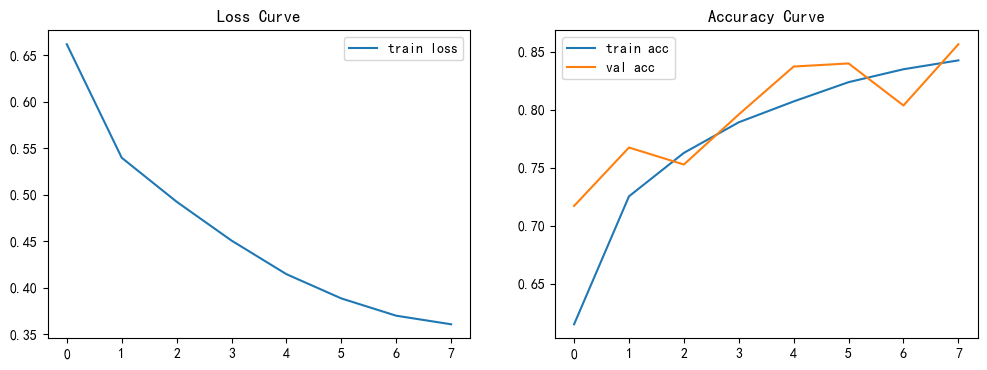

In [11]:
device  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CatDogCNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 8
train_loss_list = []
train_acc_list = []
val_loss_list = []
val_acc_list = []
best_acc = 0

for epoch in range(epochs):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)

        optimizer.zero_grad()
        out = model(imgs)
        loss = criterion(out, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        _, pred = torch.max(out, 1)
        total += labels.size(0)
        correct += (pred == labels).sum().item()
    train_loss = total_loss / len(train_loader)
    train_acc = correct / total


    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            out = model(imgs)
            loss = criterion(out, labels)

            val_loss += loss.item()
            _, pred = torch.max(out, 1)
            val_total += labels.size(0)
            val_correct += (pred == labels).sum().item()
    val_loss = val_loss / len(val_loader)
    val_acc = (val_correct / val_total)

    print(f"Epoch{epoch+1:2d} | Train loss:{train_loss:.3f} acc:{train_acc:.3f} | Val loss:{val_loss:.3f} acc:{val_acc:.3f}")
    train_loss_list.append(train_loss)
    train_acc_list.append(train_acc)      
    val_loss_list.append(val_loss)
    val_acc_list.append(val_acc)

    if val_acc > best_acc :
        best_acc = val_acc
        torch.save(model.state_dict(),"catdog_best.pth")
        print(f"保存最优模型，验证精确度{best_acc:.3f}")

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(train_loss_list, label="train loss")
plt.legend()
plt.title("Loss Curve")
plt.subplot(1,2,2)
plt.plot(train_acc_list, label="train acc")
plt.plot(val_acc_list, label="val acc")
plt.legend()
plt.title("Accuracy Curve")
plt.show()
    

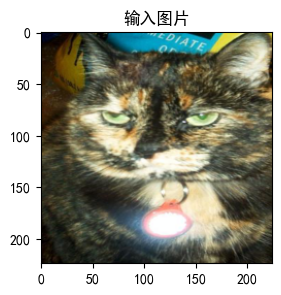

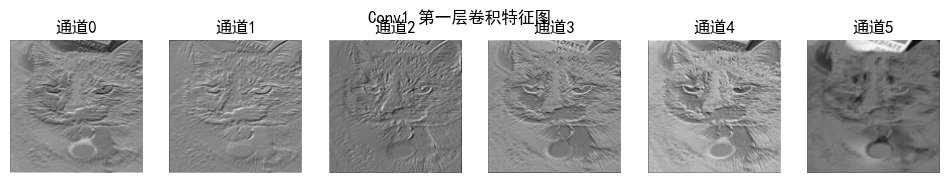

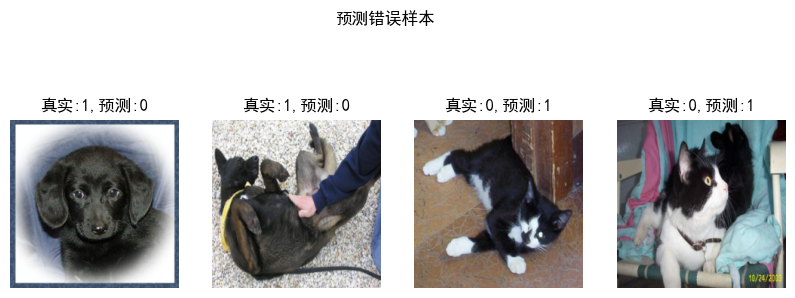

In [12]:
def show_tensor_img(tensor):
    img = tensor.clone().permute(1, 2, 0).cpu().numpy()
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = std * img + mean
    img = np.clip(img, 0, 1)
    plt.imshow(img)
    
feature_map = []
def hook_fn(module, input, output):
    feature_map.append(output)

handle = model.conv1.register_forward_hook(hook_fn)

model.eval()
img_test, label_test = test_dataset[0]
plt.figure(figsize=(3,3))
show_tensor_img(img_test)
plt.title("输入图片")
plt.show()

with torch.no_grad():
    model(img_test.unsqueeze(0).to(device))

fm = feature_map[0].squeeze(0).cpu()

plt.figure(figsize=(12,2))
for i in range(6):
    plt.subplot(1,6,i+1)
    plt.imshow(fm[i], cmap="gray")
    plt.title(f"通道{i}")
    plt.axis("off")
plt.suptitle("Conv1 第一层卷积特征图")
plt.show()

handle.remove()

error_samples = []
model.eval()
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        out = model(imgs)
        _, pred = torch.max(out, dim=1)
        for i in range(len(labels)):
            if pred[i] != labels[i]:
                error_samples.append( (imgs[i].cpu(), labels[i].item(), pred[i].item()) )
            if len(error_samples)>=4:
                break
        if len(error_samples)>=4:
            break

plt.figure(figsize=(10,4))
for idx, (img, gt, pred) in enumerate(error_samples):
    plt.subplot(1,4,idx+1)
    show_tensor_img(img)
    plt.title(f"真实:{gt},预测:{pred}")
    plt.axis("off")
plt.suptitle("预测错误样本")
plt.show()


In [13]:
from PIL import Image

predict_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

def predict_image(img_path):
    net = CatDogCNN()
    net.load_state_dict(torch.load("catdog_best.pth", map_location=device))
    net.eval()

    img = Image.open(img_test).convert("RGB")
    tensor_img = predict_transform(img).unsqueeze(0).to(device)
    with torch.no_grad():
        logits = net(tensor_img)
        prob = torch.softmax(logits, dim=1)
        cat_p = prob[0,0].item()
        dog_p = prob[0,1].item()
    pred_class = "猫" if cat_p>dog_p else "狗"
    print(f"预测类别：{pred_class}")
    print(f"猫概率：{cat_p:.4f}, 狗概率：{dog_p:.4f}")
    plt.imshow(img)
    plt.title(f"预测:{pred_class}")
    plt.axis("off")
    plt.show()
    return img, cat_p, dog_p
